# Classification

Based on Chapter 3 of *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd edition) by Aurélien Géron. Parts 2 and 3 reuse code from the book's notebook `03_classification.ipynb` (https://github.com/ageron/handson-ml3).

**Contents**

1. K-Nearest Neighbors (KNN)
2. Performance measures
3. Multiclass classification and error analysis

# Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

# 1. K-Nearest Neighbors (KNN)

To classify a new sample, KNN finds the **k** training samples closest to it and takes a majority vote among their labels.

There is no real training step: `fit()` only stores the training data. The work happens in `predict()`, when the distances to all training samples are computed.

## 1.1 A small example

Predicting a T-shirt size (M or L) from height and weight:

In [25]:
X = np.array([[158, 58], [160, 59], [163, 61], [165, 64], [168, 66],
              [170, 68], [173, 70], [175, 72], [178, 75], [180, 78]])  # height (cm), weight (kg)
y = np.array(["M", "M", "M", "M", "M", "L", "L", "L", "L", "L"])

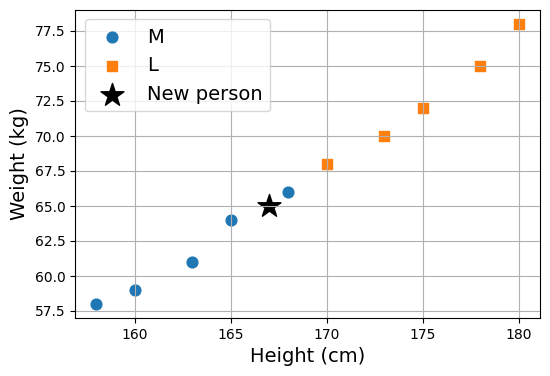

In [26]:
plt.figure(figsize=(6, 4))
plt.scatter(X[y == "M", 0], X[y == "M", 1], marker="o", s=60, label="M")
plt.scatter(X[y == "L", 0], X[y == "L", 1], marker="s", s=60, label="L")
plt.scatter([167], [65], marker="*", s=300, c="k", label="New person")
plt.xlabel("Height (cm)")
plt.ylabel("Weight (kg)")
plt.legend()
plt.grid()
plt.show()

In [54]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X, y)
knn.predict([[167, 65]])

array(['M'], dtype='<U1')

`predict_proba()` gives the share of the votes for each class. The columns follow the order of `knn.classes_`:

In [48]:
knn.classes_

array(['L', 'M'], dtype='<U1')

In [55]:
knn.predict_proba([[167, 65]])

array([[0.33333333, 0.66666667]])

`kneighbors()` shows which training samples were used, and how far they are:

In [40]:
distances, indices = knn.kneighbors([[167, 65]])
distances, indices

(array([[1.41421356, 2.23606798, 4.24264069]]), array([[4, 3, 5]]))

In [41]:
y[indices]

array([['M', 'M', 'L']], dtype='<U1')

## 1.2 KNN for regression

`KNeighborsRegressor` predicts the **average** target value of the k nearest neighbors. Apartment price (in millions) from its area (m²):

In [42]:
from sklearn.neighbors import KNeighborsRegressor

X_area = np.array([[50], [60], [70], [80], [90], [100], [120], [150]])
y_price = np.array([0.9, 1.1, 1.3, 1.5, 1.6, 1.8, 2.2, 2.8])

knn_reg = KNeighborsRegressor(n_neighbors=2)
knn_reg.fit(X_area, y_price)
knn_reg.predict([[75], [140]])

array([1.4, 2.5])

For 75 m², the two nearest apartments are 70 m² and 80 m², so the prediction is (1.3 + 1.5) / 2 = 1.4.

## 1.3 Choosing k

With a small k the model follows the training data too closely (overfitting). With a large k it averages over too many points (underfitting). Let's see this on a toy dataset with two classes:

In [56]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X_moons, y_moons = make_moons(n_samples=300, noise=0.3, random_state=42)
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_moons, y_moons, test_size=0.3, random_state=42)

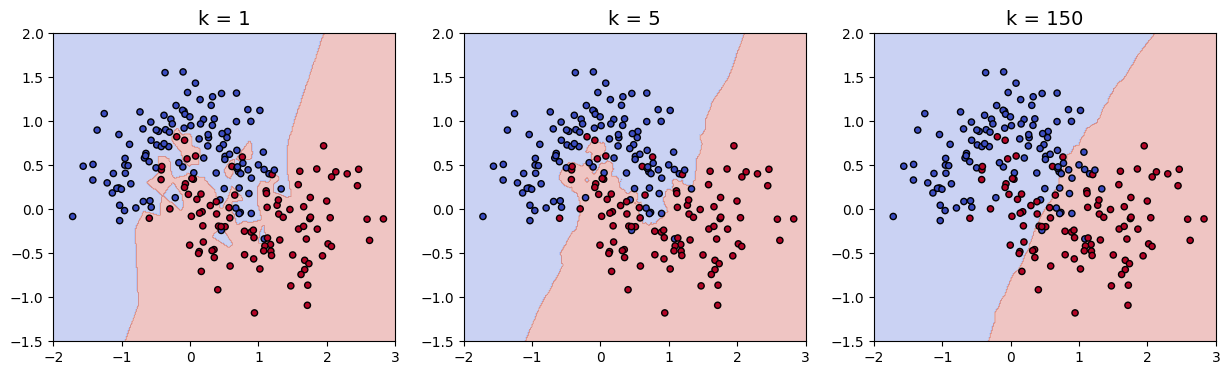

In [61]:
def plot_decision_boundary(clf, X, y, ax):
    x0, x1 = np.meshgrid(np.linspace(-2, 3, 300), np.linspace(-1.5, 2, 300))
    X_grid = np.c_[x0.ravel(), x1.ravel()]
    y_grid = clf.predict(X_grid).reshape(x0.shape)
    ax.contourf(x0, x1, y_grid, alpha=0.3, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k", s=20)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, k in zip(axes, [1, 5, 150]):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_m, y_train_m)
    plot_decision_boundary(knn, X_train_m, y_train_m, ax)
    ax.set_title(f"k = {k}")
plt.show()

In [63]:
for k in [1, 3, 5, 15, 50, 150]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_m, y_train_m)
    print(f"k = {k:<4} train accuracy: {knn.score(X_train_m, y_train_m):.3f}   "
          f"test accuracy: {knn.score(X_test_m, y_test_m):.3f}")

k = 1    train accuracy: 1.000   test accuracy: 0.867
k = 3    train accuracy: 0.938   test accuracy: 0.900
k = 5    train accuracy: 0.914   test accuracy: 0.922
k = 15   train accuracy: 0.886   test accuracy: 0.911
k = 50   train accuracy: 0.881   test accuracy: 0.900
k = 150  train accuracy: 0.781   test accuracy: 0.800


With k = 1 the model is perfect on the training set but not on the test set. With a very large k it is poor on both.

In practice, choose k with a validation set or cross-validation, never with the test set.

## 1.4 KNN needs feature scaling

KNN compares distances, so a feature with large values dominates the distance. In the wine dataset, `proline` goes up to about 1,700 while `hue` stays below 2:

In [68]:
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)
X_wine, y_wine = wine.data, wine.target
X_wine[["proline", "hue"]].describe()

,proline,hue
count,178.000000,178.000000
mean,746.893258,0.957449
std,314.907474,0.228572
min,278.000000,0.480000
25%,500.500000,0.782500
50%,673.500000,0.965000
75%,985.000000,1.120000
max,1680.000000,1.710000


In [69]:
X_train_w, X_test_w, y_train_w, y_test_w = train_test_split(
    X_wine, y_wine, test_size=0.3, stratify=y_wine, random_state=42)

Without scaling:

In [70]:
knn = KNeighborsClassifier()
knn.fit(X_train_w, y_train_w)
knn.score(X_test_w, y_test_w)

0.7222222222222222

With scaling (the scaler is fitted on the training set only, as in Chapter 2):

In [71]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_w_scaled = scaler.fit_transform(X_train_w)
X_test_w_scaled = scaler.transform(X_test_w)

knn = KNeighborsClassifier()
knn.fit(X_train_w_scaled, y_train_w)
knn.score(X_test_w_scaled, y_test_w)

0.9444444444444444

Same model, same data. Only the scaling changed.

# 2. Performance Measures

From here on we use MNIST, as in the book: 70,000 small images of handwritten digits.

## 2.1 MNIST

In [72]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', as_frame=False)
X, y = mnist.data, mnist.target
X.shape, y.shape

((70000, 784), (70000,))

Each image has 28 × 28 = 784 pixels. Each pixel goes from 0 (white) to 255 (black).

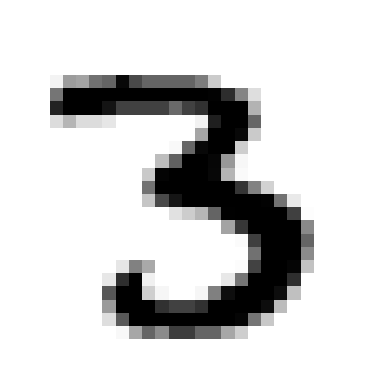

In [95]:
def plot_digit(image_data):
    image = image_data.reshape(28, 28)
    plt.imshow(image, cmap="binary")
    plt.axis("off")

some_digit = X[12]
plot_digit(some_digit)
plt.show()

In [93]:
y[12]

'3'

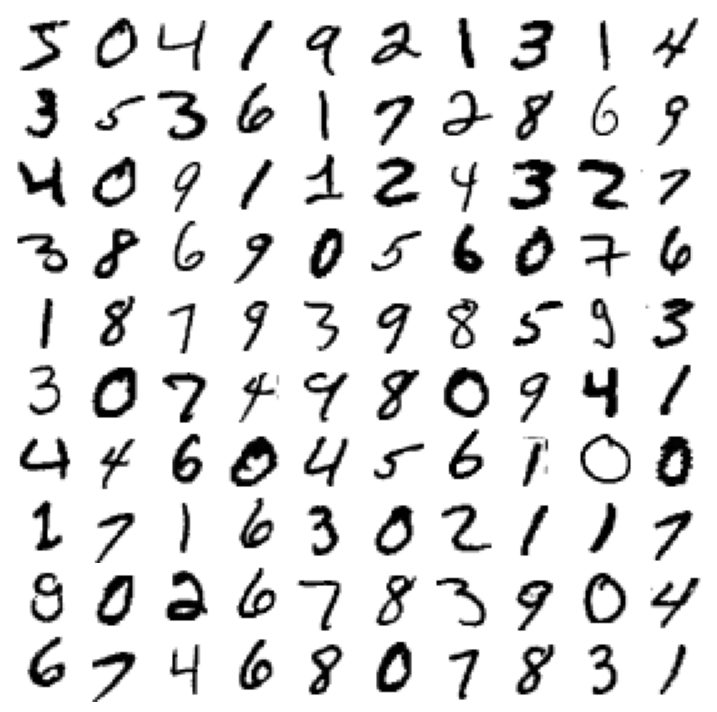

In [96]:
# extra code – plots the first 100 digits (Figure 3–2)
plt.figure(figsize=(9, 9))
for idx, image_data in enumerate(X[:100]):
    plt.subplot(10, 10, idx + 1)
    plot_digit(image_data)
plt.subplots_adjust(wspace=0, hspace=0)
plt.show()

The dataset is already split: the first 60,000 images are the training set and the last 10,000 the test set. The training set is already shuffled.

In [97]:
X_train, X_test, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]

KNN compares each new image with **every** training image, so it gets slow with 60,000 images. In this section we train KNN on the first 10,000 training images:

In [98]:
X_train_small, y_train_small = X_train[:10_000], y_train[:10_000]

## 2.2 A binary classifier: is it a 5?

In [99]:
y_train_5 = (y_train == '5')  # True for all 5s, False for all other digits
y_train_small_5 = y_train_5[:10_000]

In [100]:
knn_clf = KNeighborsClassifier()
knn_clf.fit(X_train_small, y_train_small_5)
knn_clf.predict([some_digit])

/Users/georgemichael/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/georgemichael/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/georgemichael/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


array([False])

## 2.3 Accuracy

Accuracy with 3-fold cross-validation:

In [101]:
from sklearn.model_selection import cross_val_score

cross_val_score(knn_clf, X_train_small, y_train_small_5, cv=3, scoring="accuracy")

/Users/georgemichael/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/georgemichael/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/georgemichael/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/georgemichael/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/georgemichael/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/georgemichael/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/georgemichael/Library/Python/3.9/li

array([0.98620276, 0.98949895, 0.98529853])

Above 98%. Now compare with a model that always answers "not 5":

In [102]:
from sklearn.dummy import DummyClassifier

dummy_clf = DummyClassifier()
dummy_clf.fit(X_train_small, y_train_small_5)
print(any(dummy_clf.predict(X_train_small)))

False


In [103]:
cross_val_score(dummy_clf, X_train_small, y_train_small_5, cv=3, scoring="accuracy")

array([0.91361728, 0.91359136, 0.91389139])

Over 91% accuracy without even looking at the images, simply because only about 9% of the images are 5s.

Accuracy is misleading when one class is much more frequent than the others (a *skewed* dataset).

## 2.4 Confusion matrix

A confusion matrix counts how many samples of each class were predicted as each class.

`cross_val_predict()` gives a prediction for every training image, each one made by a model that did not see that image during training:

In [ ]:
from sklearn.model_selection import cross_val_predict

y_train_pred = cross_val_predict(knn_clf, X_train_small, y_train_small_5, cv=3)

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_train_small_5, y_train_pred)
cm

|                   | Predicted: not 5     | Predicted: 5         |
|-------------------|----------------------|----------------------|
| **Actual: not 5** | TN (true negatives)  | FP (false positives) |
| **Actual: 5**     | FN (false negatives) | TP (true positives)  |

A perfect classifier only has non-zero values on the main diagonal:

In [ ]:
y_train_perfect_predictions = y_train_small_5  # pretend we reached perfection
confusion_matrix(y_train_small_5, y_train_perfect_predictions)

## 2.5 Precision, recall and F1

- **Precision** = TP / (TP + FP): when the model says "5", how often is it right?
- **Recall** = TP / (TP + FN): out of all the real 5s, how many did it find?
- **F1 score** = 2 × precision × recall / (precision + recall): the harmonic mean of the two. It is high only if both are high.

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision_score(y_train_small_5, y_train_pred)

In [ ]:
# extra code – the same precision from the confusion matrix: TP / (FP + TP)
cm[1, 1] / (cm[0, 1] + cm[1, 1])

In [ ]:
recall_score(y_train_small_5, y_train_pred)

In [ ]:
# extra code – the same recall from the confusion matrix: TP / (FN + TP)
cm[1, 1] / (cm[1, 0] + cm[1, 1])

In [ ]:
f1_score(y_train_small_5, y_train_pred)

Which one matters more depends on the problem:

- Spam filter: marking a real email as spam is costly, so we want high **precision**.
- Disease screening: missing a sick patient is costly, so we want high **recall**.

## 2.6 Precision/recall trade-off

Behind every prediction there is a **score** that is compared with a **threshold**. Raising the threshold increases precision and lowers recall. Lowering it does the opposite.

For KNN, the score is the share of the votes. With k = 5 it can only take 6 values:

In [ ]:
y_probas_knn = cross_val_predict(knn_clf, X_train_small, y_train_small_5, cv=3,
                                 method="predict_proba")
np.unique(y_probas_knn[:, 1])

So there are only a few thresholds to choose from. To see the whole trade-off we use the classifier from the book, `SGDClassifier`: a linear model (Chapter 4) that outputs a continuous score. It is fast, so as in the book we train it on the full training set:

In [ ]:
from sklearn.linear_model import SGDClassifier

sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(X_train, y_train_5)

In [ ]:
y_scores = sgd_clf.decision_function([some_digit])
y_scores

In [ ]:
threshold = 0
y_some_digit_pred = (y_scores > threshold)
y_some_digit_pred

In [ ]:
threshold = 3000
y_some_digit_pred = (y_scores > threshold)
y_some_digit_pred

Raising the threshold to 3,000 turns this 5 into a miss. To choose a threshold, we first get the scores of all training images:

In [ ]:
y_scores = cross_val_predict(sgd_clf, X_train, y_train_5, cv=3,
                             method="decision_function")

In [ ]:
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(y_train_5, y_scores)

In [ ]:
plt.figure(figsize=(8, 4))  # extra code – it's not needed, just formatting
plt.plot(thresholds, precisions[:-1], "b--", label="Precision", linewidth=2)
plt.plot(thresholds, recalls[:-1], "g-", label="Recall", linewidth=2)
plt.vlines(threshold, 0, 1.0, "k", "dotted", label="threshold")

# extra code – this section just beautifies Figure 3–5
idx = (thresholds >= threshold).argmax()  # first index ≥ threshold
plt.plot(thresholds[idx], precisions[idx], "bo")
plt.plot(thresholds[idx], recalls[idx], "go")
plt.axis([-50000, 50000, 0, 1])
plt.grid()
plt.xlabel("Threshold")
plt.legend(loc="center right")

plt.show()

In [ ]:
import matplotlib.patches as patches  # extra code – for the curved arrow

plt.figure(figsize=(6, 5))  # extra code – not needed, just formatting

plt.plot(recalls, precisions, linewidth=2, label="Precision/Recall curve")

# extra code – just beautifies Figure 3–6
plt.plot([recalls[idx], recalls[idx]], [0., precisions[idx]], "k:")
plt.plot([0.0, recalls[idx]], [precisions[idx], precisions[idx]], "k:")
plt.plot([recalls[idx]], [precisions[idx]], "ko",
         label="Point at threshold 3,000")
plt.gca().add_patch(patches.FancyArrowPatch(
    (0.79, 0.60), (0.61, 0.78),
    connectionstyle="arc3,rad=.2",
    arrowstyle="Simple, tail_width=1.5, head_width=8, head_length=10",
    color="#444444"))
plt.text(0.56, 0.62, "Higher\nthreshold", color="#333333")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.axis([0, 1, 0, 1])
plt.grid()
plt.legend(loc="lower left")

plt.show()

Suppose we want 90% precision. We search for the lowest threshold that gives at least 90%:

In [ ]:
idx_for_90_precision = (precisions >= 0.90).argmax()
threshold_for_90_precision = thresholds[idx_for_90_precision]
threshold_for_90_precision

In [ ]:
y_train_pred_90 = (y_scores >= threshold_for_90_precision)
precision_score(y_train_5, y_train_pred_90)

In [ ]:
recall_at_90_precision = recall_score(y_train_5, y_train_pred_90)
recall_at_90_precision

We got 90% precision, but the recall dropped to about 48%. High precision is not very useful if the recall is too low.

## 2.7 The ROC curve

The ROC curve plots the **true positive rate** (recall) against the **false positive rate** (the share of negatives wrongly classified as positive), for every possible threshold. A perfect classifier reaches the top-left corner. A random classifier follows the diagonal.

In [ ]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_train_5, y_scores)

In [ ]:
idx_for_threshold_at_90 = (thresholds <= threshold_for_90_precision).argmax()
tpr_90, fpr_90 = tpr[idx_for_threshold_at_90], fpr[idx_for_threshold_at_90]

plt.figure(figsize=(6, 5))  # extra code – not needed, just formatting
plt.plot(fpr, tpr, linewidth=2, label="ROC curve")
plt.plot([0, 1], [0, 1], 'k:', label="Random classifier's ROC curve")
plt.plot([fpr_90], [tpr_90], "ko", label="Threshold for 90% precision")

# extra code – just beautifies Figure 3–7
plt.gca().add_patch(patches.FancyArrowPatch(
    (0.20, 0.89), (0.07, 0.70),
    connectionstyle="arc3,rad=.4",
    arrowstyle="Simple, tail_width=1.5, head_width=8, head_length=10",
    color="#444444"))
plt.text(0.12, 0.71, "Higher\nthreshold", color="#333333")
plt.xlabel('False Positive Rate (Fall-Out)')
plt.ylabel('True Positive Rate (Recall)')
plt.grid()
plt.axis([0, 1, 0, 1])
plt.legend(loc="lower right", fontsize=13)

plt.show()

The **AUC** (area under the ROC curve) summarizes the curve in one number: 1 for a perfect classifier, 0.5 for a random one.

In [ ]:
from sklearn.metrics import roc_auc_score

roc_auc_score(y_train_5, y_scores)

**ROC or precision/recall curve?** Prefer the precision/recall curve when the positive class is rare (like the 5s here) or when false positives matter more than false negatives. Otherwise use the ROC curve.

Here the ROC curve and the AUC look very good, mostly because there are few 5s. The precision/recall curve shows that there is still a lot of room for improvement.

# 3. Multiclass Classification and Error Analysis

KNN works with several classes directly: the vote is simply between all ten digits.

Some models, such as SVMs, are strictly binary. For those, Scikit-Learn automatically trains several binary classifiers (one-versus-rest or one-versus-one).

In [ ]:
knn_clf = KNeighborsClassifier()
knn_clf.fit(X_train_small, y_train_small)  # y_train_small, not y_train_small_5
knn_clf.predict([some_digit])

In [ ]:
knn_clf.classes_

In [ ]:
knn_clf.predict_proba([some_digit])

In [ ]:
cross_val_score(knn_clf, X_train_small, y_train_small, cv=3, scoring="accuracy")

A random guess would get about 10%.

## 3.1 Error analysis

The confusion matrix shows which digits the model mixes up. Rows are the true digits, columns the predicted ones:

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

y_train_pred = cross_val_predict(knn_clf, X_train_small, y_train_small, cv=3)
plt.rc('font', size=9)  # extra code – make the text smaller
ConfusionMatrixDisplay.from_predictions(y_train_small, y_train_pred)
plt.show()

Dividing each row by the number of images of that digit:

In [ ]:
plt.rc('font', size=10)  # extra code
ConfusionMatrixDisplay.from_predictions(y_train_small, y_train_pred,
                                        normalize="true", values_format=".0%")
plt.show()

Keeping only the errors makes them easier to see:

In [ ]:
sample_weight = (y_train_pred != y_train_small)
plt.rc('font', size=10)  # extra code
ConfusionMatrixDisplay.from_predictions(y_train_small, y_train_pred,
                                        sample_weight=sample_weight,
                                        normalize="true", values_format=".0%")
plt.show()

For example, many of the errors on 4s are 4s predicted as 9s. Let's look at some of these images:

In [ ]:
cl_a, cl_b = '4', '9'
X_aa = X_train_small[(y_train_small == cl_a) & (y_train_pred == cl_a)]
X_ab = X_train_small[(y_train_small == cl_a) & (y_train_pred == cl_b)]
X_ba = X_train_small[(y_train_small == cl_b) & (y_train_pred == cl_a)]
X_bb = X_train_small[(y_train_small == cl_b) & (y_train_pred == cl_b)]

In [ ]:
# extra code – same plot as Figure 3–11, for 4s and 9s
size = 5
pad = 0.2
plt.figure(figsize=(size, size))
for images, (label_col, label_row) in [(X_ba, (0, 0)), (X_bb, (1, 0)),
                                       (X_aa, (0, 1)), (X_ab, (1, 1))]:
    for idx, image_data in enumerate(images[:size*size]):
        x = idx % size + label_col * (size + pad)
        y = idx // size + label_row * (size + pad)
        plt.imshow(image_data.reshape(28, 28), cmap="binary",
                   extent=(x, x + 1, y, y + 1))
plt.xticks([size / 2, size + pad + size / 2], [str(cl_a), str(cl_b)])
plt.yticks([size / 2, size + pad + size / 2], [str(cl_b), str(cl_a)])
plt.plot([size + pad / 2, size + pad / 2], [0, 2 * size + pad], "k:")
plt.plot([0, 2 * size + pad], [size + pad / 2, size + pad / 2], "k:")
plt.axis([0, 2 * size + pad, 0, 2 * size + pad])
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.show()

The top-left and bottom-right blocks are correct predictions; the other two are errors. Would you classify all of these errors correctly yourself?

# Homework

1. Exercise 1 of Chapter 3: build a KNN classifier for MNIST with over 97% accuracy on the test set. Hint: try `GridSearchCV` on the `weights` and `n_neighbors` hyperparameters, using a subset of the training set first.
2. Repeat Part 2 with another digit instead of 5 (for example 8). Are the precision and recall better or worse?